# Lab 8 - Generative Deep Learning
**Dataset link:** https://www.kaggle.com/datasets/moltean/fruits

*(Using Test/Apple 10 with 231 images)*

### Install libraries

In [1]:
%pip install tensorflow numpy matplotlib pillow

Note: you may need to restart the kernel to use updated packages.


### Import libraries

In [2]:
import os
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from PIL import Image
from tensorflow.keras import layers, Model

### Configuration

In [3]:
# Dataset configuration
DATASET_DIR = Path(r"D:\COS30082\labs\lab08\lab08_dataset")

# Image configuration
IMAGE_SIZE = 64
CHANNELS = 3

# Dataset configuration
NUM_IMAGES = 300

# GAN configuration
LATENT_DIM = 100
BATCH_SIZE = 16
EPOCHS = 1000

# Reproducibility
SEED = 42

np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Dataset directory:", DATASET_DIR)
print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)
print("Epochs:", EPOCHS)

Dataset directory: D:\COS30082\labs\lab08\lab08_dataset
Image size: 64
Batch size: 16
Epochs: 1000


### Load Dataset

In [4]:
# Find JPEG images
image_paths = sorted(
    list(DATASET_DIR.rglob("*.jpg")) +
    list(DATASET_DIR.rglob("*.jpeg")) +
    list(DATASET_DIR.rglob("*.JPG")) +
    list(DATASET_DIR.rglob("*.JPEG"))
)

# Remove duplicate paths, if any
image_paths = list(dict.fromkeys(image_paths))

if len(image_paths) < 100:
    raise ValueError(
        f"Only {len(image_paths)} images found. "
        "Please check the dataset directory."
    )

# Select up to NUM_IMAGES images
image_paths = image_paths[:NUM_IMAGES]

print("Number of images found and selected:", len(image_paths))

Number of images found and selected: 231


### Preprocessing

In [5]:
images = []

for image_path in image_paths:
    try:
        # Open image and convert to RGB
        image = Image.open(image_path).convert("RGB")

        # Resize image
        image = image.resize(
            (IMAGE_SIZE, IMAGE_SIZE),
            Image.Resampling.LANCZOS
        )

        # Convert image to NumPy array
        image = np.array(image, dtype=np.float32)

        # Normalize pixels from [0, 255] to [-1, 1]
        image = (image / 127.5) - 1.0

        images.append(image)

    except Exception as error:
        print(f"Skipping {image_path}: {error}")

# Convert to a NumPy array
images = np.array(images, dtype=np.float32)

print("Dataset shape:", images.shape)
print("Minimum pixel value:", images.min())
print("Maximum pixel value:", images.max())

train_dataset = (
    tf.data.Dataset.from_tensor_slices(images)
    .shuffle(buffer_size=len(images), seed=SEED)
    .batch(BATCH_SIZE, drop_remainder=True)
    .prefetch(tf.data.AUTOTUNE)
)


print("Number of images:", len(images))
print("Number of batches:", len(train_dataset))

Dataset shape: (231, 64, 64, 3)
Minimum pixel value: -1.0
Maximum pixel value: 1.0
Number of images: 231
Number of batches: 14


### Visualization

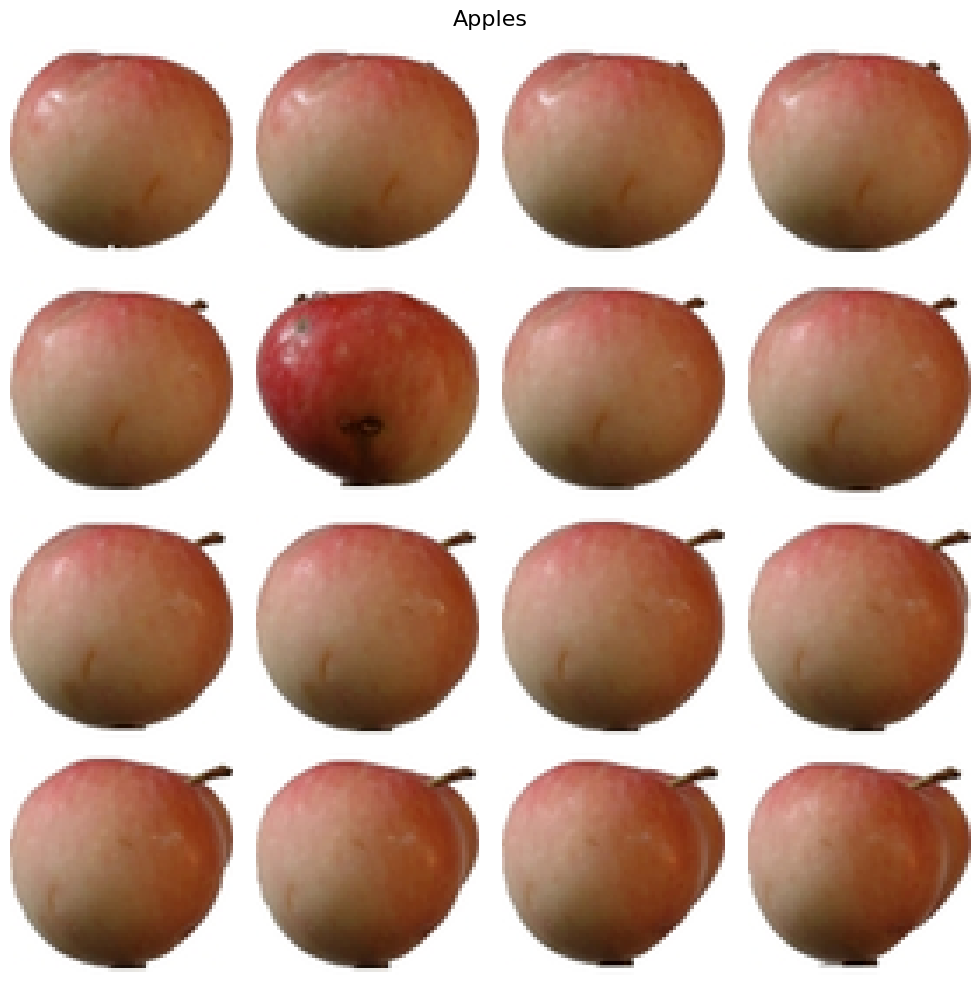

In [6]:
plt.figure(figsize=(10, 10))

for i in range(min(16, len(images))):
    # Convert pixels from [-1, 1] back to [0, 1]
    display_image = (images[i] + 1.0) / 2.0

    plt.subplot(4, 4, i + 1)
    plt.imshow(display_image)
    plt.axis("off")

plt.suptitle("Apples", fontsize=16)
plt.tight_layout()
plt.show()

### Models

1. Building Untrained Generator

In [7]:
def build_generator():
    model = tf.keras.Sequential([
        layers.Input(shape=(LATENT_DIM,)),

        layers.Dense(4 * 4 * 256, use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Reshape((4, 4, 256)),

        layers.Conv2DTranspose(
            128, 4, strides=2, padding="same", use_bias=False
        ),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Conv2DTranspose(
            64, 4, strides=2, padding="same", use_bias=False
        ),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Conv2DTranspose(
            32, 4, strides=2, padding="same", use_bias=False
        ),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Conv2DTranspose(
            CHANNELS, 4, strides=2,
            padding="same", activation="tanh"
        )
    ], name="Generator")

    return model


generator = build_generator()
generator.summary()

Model: "Generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 4096)           │       409,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 4096)           │        16,384 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 8, 8, 128)      │       524,288 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 16, 16, 64)     │       131,072 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 32, 32, 32)     │        32,768 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_3              │ (None, 64, 64, 3)      │         1,539 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,116,547 (4.26 MB)

 Trainable params: 1,107,907 (4.23 MB)

 Non-trainable params: 8,640 (33.75 KB)

2. Untrained Discriminator

In [8]:
def build_discriminator():
    model = tf.keras.Sequential([
        layers.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, CHANNELS)),

        layers.Conv2D(64, 4, strides=2, padding="same"),
        layers.LeakyReLU(negative_slope=0.2),
        layers.Dropout(0.3),

        layers.Conv2D(128, 4, strides=2, padding="same"),
        layers.LeakyReLU(negative_slope=0.2),
        layers.Dropout(0.3),

        layers.Conv2D(256, 4, strides=2, padding="same"),
        layers.LeakyReLU(negative_slope=0.2),
        layers.Dropout(0.3),

        layers.Flatten(),
        layers.Dense(1)
    ], name="Discriminator")

    return model


discriminator = build_discriminator()
discriminator.summary()

Model: "Discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 64)     │         3,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 128)    │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_5 (LeakyReLU)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 256)      │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_6 (LeakyReLU)       │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │        16,385 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 675,265 (2.58 MB)

 Trainable params: 675,265 (2.58 MB)

 Non-trainable params: 0 (0.00 B)

3. Train the Models

In [9]:
SAMPLE_DIR = "apple_samples"
CHECKPOINT_DIR = "apple_checkpoints"

os.makedirs(SAMPLE_DIR, exist_ok=True)
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

SAVE_SAMPLE_EVERY = 10
SAVE_MODEL_EVERY = 20

# Fixed noise allows us to compare the same generated images throughout training
fixed_noise = tf.random.normal(
    shape=(16, LATENT_DIM),
    seed=SEED
)

# Save the generator's initial output before training
images_before = generator(
    fixed_noise,
    training=False
).numpy()


# Loss functions
cross_entropy = tf.keras.losses.BinaryCrossentropy(
    from_logits=True
)


def discriminator_loss(real_output, fake_output):
    real_loss = cross_entropy(
        tf.ones_like(real_output),
        real_output
    )

    fake_loss = cross_entropy(
        tf.zeros_like(fake_output),
        fake_output
    )

    return real_loss + fake_loss


def generator_loss(fake_output):
    return cross_entropy(
        tf.ones_like(fake_output),
        fake_output
    )


# Optimizers

generator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0002,
    beta_1=0.5
)

discriminator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0002,
    beta_1=0.5
)


# Training function
@tf.function
def train_step(real_images):

    # Generate random noise for the generator
    noise = tf.random.normal(
        shape=(tf.shape(real_images)[0], LATENT_DIM)
    )

    with tf.GradientTape() as gen_tape, \
         tf.GradientTape() as disc_tape:

        # Generate fake images
        fake_images = generator(
            noise,
            training=True
        )

        # Discriminator evaluates real and fake images
        real_output = discriminator(
            real_images,
            training=True
        )

        fake_output = discriminator(
            fake_images,
            training=True
        )

        # Calculate losses
        gen_loss = generator_loss(fake_output)

        disc_loss = discriminator_loss(
            real_output,
            fake_output
        )

    # Calculate gradients
    gen_gradients = gen_tape.gradient(
        gen_loss,
        generator.trainable_variables
    )

    disc_gradients = disc_tape.gradient(
        disc_loss,
        discriminator.trainable_variables
    )

    # Update model weights
    generator_optimizer.apply_gradients(
        zip(gen_gradients, generator.trainable_variables)
    )

    discriminator_optimizer.apply_gradients(
        zip(disc_gradients, discriminator.trainable_variables)
    )

    return gen_loss, disc_loss


# Saving generated images function
def save_generated_samples(epoch):

    generated_images = generator(
        fixed_noise,
        training=False
    ).numpy()

    # Convert pixel values from [-1, 1] to [0, 1]
    generated_images = np.clip(
        (generated_images + 1.0) / 2.0,
        0.0,
        1.0
    )

    fig, axes = plt.subplots(
        4, 4,
        figsize=(8, 8)
    )

    for i, ax in enumerate(axes.flat):
        ax.imshow(generated_images[i])
        ax.axis("off")

    fig.suptitle(
        f"Generated Apple Images - Epoch {epoch}"
    )

    plt.tight_layout()

    fig.savefig(
        os.path.join(
            SAMPLE_DIR,
            f"epoch_{epoch:03d}.png"
        ),
        dpi=120
    )

    plt.close(fig)


# Training loop
generator_history = []
discriminator_history = []

for epoch in range(EPOCHS):

    gen_losses = []
    disc_losses = []

    for real_images in train_dataset:

        gen_loss, disc_loss = train_step(real_images)

        # Convert tensors to Python floats
        gen_loss_value = float(gen_loss.numpy())
        disc_loss_value = float(disc_loss.numpy())

        # Stop if training becomes numerically unstable
        if not np.isfinite(gen_loss_value):
            raise ValueError(
                f"Generator loss is invalid at epoch {epoch + 1}"
            )

        if not np.isfinite(disc_loss_value):
            raise ValueError(
                f"Discriminator loss is invalid at epoch {epoch + 1}"
            )

        gen_losses.append(gen_loss_value)
        disc_losses.append(disc_loss_value)

    # Calculate average loss for the epoch
    avg_gen_loss = np.mean(gen_losses)
    avg_disc_loss = np.mean(disc_losses)

    generator_history.append(avg_gen_loss)
    discriminator_history.append(avg_disc_loss)

    current_epoch = epoch + 1

    # Print progress every 10 epochs
    if current_epoch % SAVE_SAMPLE_EVERY == 0 or current_epoch == 1:

        print(
            f"Epoch {current_epoch}/{EPOCHS} | "
            f"Generator loss: {avg_gen_loss:.4f} | "
            f"Discriminator loss: {avg_disc_loss:.4f}"
        )

        # Save images for visual comparison
        save_generated_samples(current_epoch)

    # Save model checkpoints every 20 epochs
    if current_epoch % SAVE_MODEL_EVERY == 0:

        generator.save(
            os.path.join(
                CHECKPOINT_DIR,
                f"generator_epoch_{current_epoch}.keras"
            )
        )

        discriminator.save(
            os.path.join(
                CHECKPOINT_DIR,
                f"discriminator_epoch_{current_epoch}.keras"
            )
        )

# Save final models
generator.save("apple_generator.keras")
discriminator.save("apple_discriminator.keras")

Epoch 1/1000 | Generator loss: 0.9341 | Discriminator loss: 0.7653
Epoch 10/1000 | Generator loss: 1.4394 | Discriminator loss: 0.7734
Epoch 20/1000 | Generator loss: 1.3435 | Discriminator loss: 0.9291
Epoch 30/1000 | Generator loss: 1.1226 | Discriminator loss: 1.0987
Epoch 40/1000 | Generator loss: 1.0564 | Discriminator loss: 1.0100
Epoch 50/1000 | Generator loss: 1.0561 | Discriminator loss: 0.9692
Epoch 60/1000 | Generator loss: 0.9979 | Discriminator loss: 1.0224
Epoch 70/1000 | Generator loss: 1.0784 | Discriminator loss: 1.0054
Epoch 80/1000 | Generator loss: 1.2080 | Discriminator loss: 1.0585
Epoch 90/1000 | Generator loss: 1.2339 | Discriminator loss: 0.9555
Epoch 100/1000 | Generator loss: 1.1768 | Discriminator loss: 1.0393
Epoch 110/1000 | Generator loss: 1.1685 | Discriminator loss: 1.0354
Epoch 120/1000 | Generator loss: 1.1355 | Discriminator loss: 1.0000
Epoch 130/1000 | Generator loss: 1.1422 | Discriminator loss: 1.0009
Epoch 140/1000 | Generator loss: 1.1434 | Dis

### Generate Images

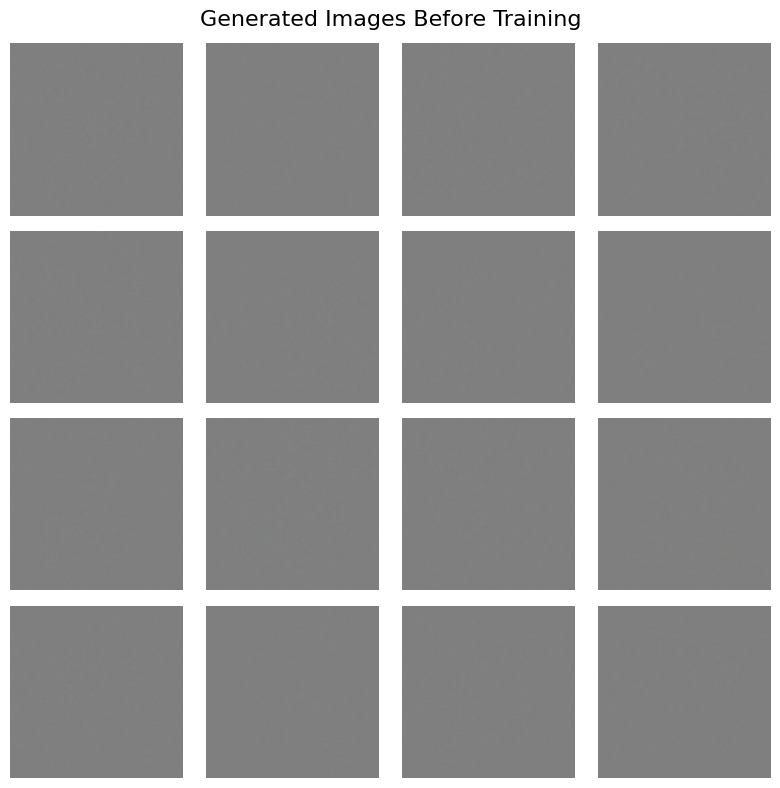

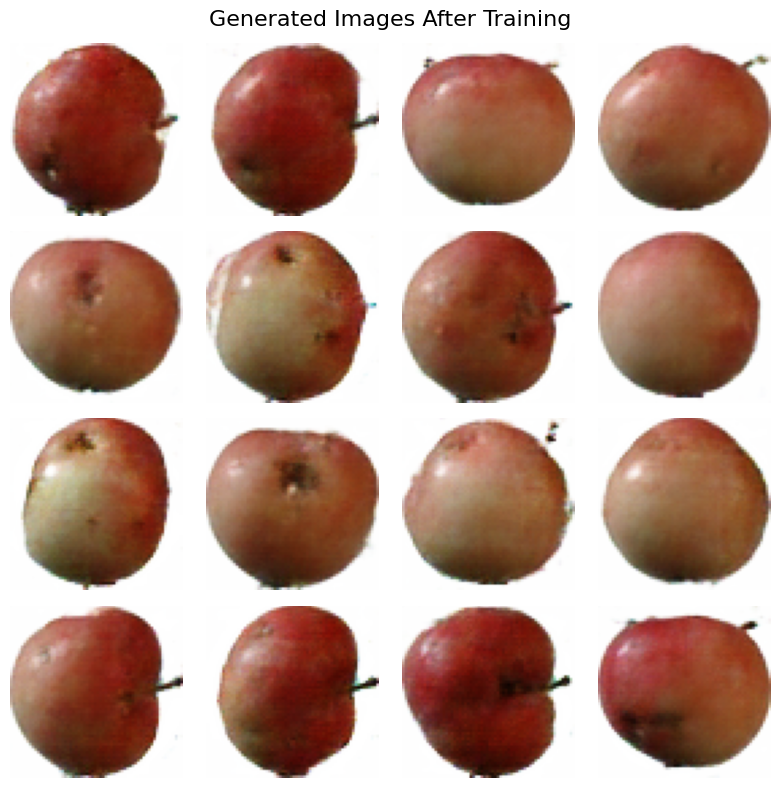

In [10]:
def show_generated_images(generated_images, title):
    # Convert from [-1, 1] to [0, 1]
    generated_images = np.clip(
        (generated_images + 1.0) / 2.0, 0.0, 1.0
    )

    plt.figure(figsize=(8, 8))

    for i in range(min(16, len(generated_images))):
        plt.subplot(4, 4, i + 1)
        plt.imshow(generated_images[i])
        plt.axis("off")

    plt.suptitle(title, fontsize=16)
    plt.tight_layout()
    plt.show()


# Before training
show_generated_images(images_before, "Generated Images Before Training")

# After training, using the same noise vectors
images_after = generator(fixed_noise, training=False).numpy()
show_generated_images(images_after, "Generated Images After Training")